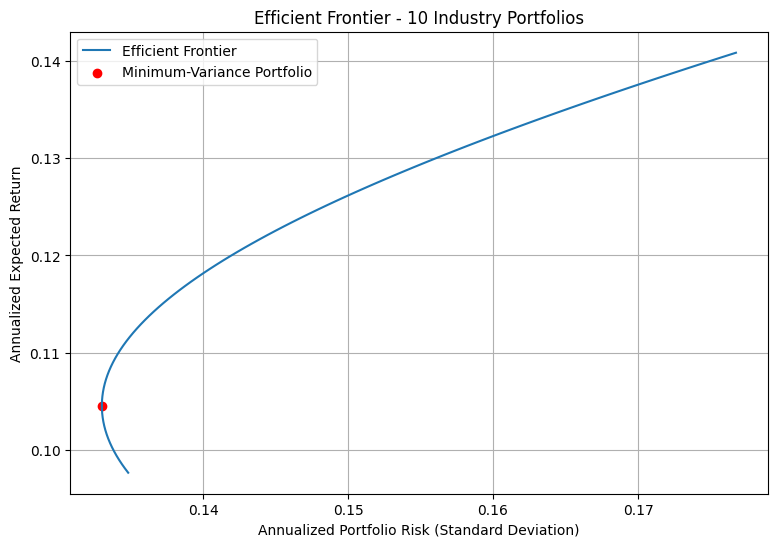

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from methods import my_min_variance



SRC_DIR = Path.cwd().resolve()
PROJECT_ROOT = SRC_DIR.parent

DATA_PATH = PROJECT_ROOT / "data" / "10_Industry_Portfolios.csv"
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(
    DATA_PATH,
    skiprows=11,
    nrows=1203,
    index_col=0
)

data = data.apply(pd.to_numeric, errors="coerce")
data = data.replace([-99.99, -999], np.nan)
data = data.dropna()
data = data / 100

# Estimate monthly parameters
mu_monthly = data.mean()
Sigma_monthly = data.cov()

# Annualize estimates
mu_annual = mu_monthly * 12
Sigma_annual = Sigma_monthly * 12

mu = mu_annual.to_numpy()
Sigma = Sigma_annual.to_numpy()

one = np.ones(len(mu))

# Calculate efficient frontier constants
Si1 = np.linalg.solve(Sigma, one)
Simu = np.linalg.solve(Sigma, mu)

a = one @ Si1
b = one @ Simu
c = mu @ Simu

D = a * c - b**2


target_returns = np.linspace(mu.min(), mu.max(), 100)

portfolio_risks = []

for r in target_returns:
    lam = (a * r - b) / D
    gamma = (c - b * r) / D

    w = lam * Simu + gamma * Si1

    variance = w @ Sigma @ w
    risk = np.sqrt(variance)

    portfolio_risks.append(risk)

portfolio_risks = np.array(portfolio_risks)

# Calculate minimum-variance portfolio
w_min = my_min_variance(Sigma)

min_return = w_min @ mu
min_risk = np.sqrt(w_min @ Sigma @ w_min)


plt.figure(figsize=(9, 6))

plt.plot(
    portfolio_risks,
    target_returns,
    label="Efficient Frontier"
)

plt.scatter(
    min_risk,
    min_return,
    color="red",
    label="Minimum-Variance Portfolio"
)

plt.xlabel("Annualized Portfolio Risk (Standard Deviation)")
plt.ylabel("Annualized Expected Return")
plt.title("Efficient Frontier - 10 Industry Portfolios")
plt.legend()
plt.grid(True)

plt.savefig(
    FIGURES_DIR / "efficient_frontier.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()